# Hệ thống Phân tích Cảm xúc TikTok Song ngữ (Tiếng Việt & Tiếng Anh)

- **Nguồn đầu vào (2 chế độ):** **1. Link TikTok** (Chuẩn bị dữ liệu: tự tải video/ảnh, crawl comment + reply và phân tích nội dung video lưu vào `data/<post_id>/`) hoặc **2. Thư mục đã chuẩn bị sẵn** (`data/<post_id>/` chứa `raw_comments.csv`, video/ảnh & `media_context.json`).
- **Chuẩn bị dữ liệu & Giai đoạn 1 (`gemma4-e2b-opt` + Whisper):** Trích khung hình có mốc thời gian (`768px`, tự động 2-pass cho slideshow dài) + lời thoại Whisper + caption thành JSON Evidence-First (11 trường) và lưu vào `data/<post_id>/media_context.json` để tái sử dụng cho Giai đoạn 2–3 mà không cần chạy lại Gemma 4.
- **Giai đoạn 2 — Tiền xử lý & Lọc nhiễu có ngữ cảnh (`src/preprocessing/text_cleaner.py`):** Nhận diện ngôn ngữ (`vi` / `en`), bảo vệ thực thể video không bị lọc nhầm, lọc nhiễu, tách từ `underthesea` và tính độ liên quan chủ đề (`is_on_topic`, `context_relevance`).
- **Giai đoạn 3 — Lõi ML & Deep Learning (`src/models/classical_ml.py` + `sentiment_engine.py`):** Giữ chuẩn NLP đánh giá cảm xúc từng bình luận (`TF-IDF NB/LR/SVM`, `Lexicon`, `ViSoBERT`, `PhoBERT`, `Twitter-RoBERTa`, `Emotion 7 cung bậc`) kết hợp tầng Context Alignment (`context_alignment` xuất tại `detailed_model_outputs.csv`).
- **Giai đoạn 4 — AI Đầu ra (`src/models/gemma_auditor.py`, mặc định TẮT):** Khi bật `RUN_AI_AUDIT = True`, `gemma4-e2b-opt` thẩm định các ca mỉa mai sâu & kết quả Giai đoạn 3 dựa trên `media_context.json`; xuất 6 tệp gọn ra `outputs/<run_name>/` (`final_results.csv` sắp theo likes, `detailed_model_outputs.csv`, `filtered_noise.csv`, `model_comparison.csv`, `report.json`, `dashboard.png`).

> Lưu ý: Chỉ cần khởi động container Ollama `gemma4-e2b` khi trích xuất mới `media_context.json` ở Giai đoạn 1 hoặc khi bật Giai đoạn 4 (`RUN_AI_AUDIT = True`).

In [11]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

from src.pipeline import SentimentPipeline
from src.visualization import plot_sentiment_dashboard

# === TÙY CHỌN GÁN CỨNG (để None nếu muốn notebook hỏi tương tác khi chạy) ===
INPUT_MODE = None            # None (hỏi trực tiếp) | "url" | "folder"
TIKTOK_URL = ""
INPUT_DIR = None             # Đường dẫn thư mục đã chuẩn bị sẵn (vd: "data/7711719899852295445") cho chế độ "folder"
RUN_MEDIA_ANALYSIS = True    # True = dùng/trích xuất media_context.json; False = bỏ qua ngữ cảnh video
FORCE_REANALYZE_MEDIA = False # True = ép Gemma 4 + Whisper phân tích lại dù đã có media_context.json
PREPARE_ONLY = False         # True = chỉ Chuẩn bị dữ liệu vào data/<post_id>/ rồi dừng
RUN_AI_AUDIT = False         # Mặc định TẮT Giai đoạn 4 (đặt True để bật Gemma 4 thẩm định ca mỉa mai sâu, hoặc None để hỏi)

# === CHỌN NGUỒN ĐẦU VÀO ===
if INPUT_MODE is None:
    print("Chọn nguồn dữ liệu đầu vào:")
    print("  1. Link TikTok (Chuẩn bị dữ liệu: tải media, crawl comment + reply & lưu vào data/<post_id>/)")
    print("  2. Thư mục đã chuẩn bị sẵn (vd: data/<post_id>)")
    _choice = input("Nhập lựa chọn [1/2, mặc định 1]: ").strip() or "1"
    INPUT_MODE = {"1": "url", "2": "folder"}.get(_choice, "url")

if INPUT_MODE == "url":
    if not TIKTOK_URL:
        TIKTOK_URL = input("Nhập link video/ảnh TikTok: ").strip().strip('"\'')
elif INPUT_MODE == "folder":
    if not INPUT_DIR:
        INPUT_DIR = input("Nhập đường dẫn thư mục (vd: data/7711719899852295445): ").strip().strip('"\'')
else:
    raise ValueError(f"INPUT_MODE không hợp lệ: {INPUT_MODE} (chỉ hỗ trợ 'url' hoặc 'folder').")

# === TÙY CHỌN GIAI ĐOẠN 4 (THẨM ĐỊNH BẰNG AI — MẶC ĐỊNH TẮT) ===
if RUN_AI_AUDIT is None:
    _ans = input("Có chạy Giai đoạn 4 (dùng AI Gemma 4 thẩm định ca mỉa mai sâu & kết quả Giai đoạn 3) không? [y/N, mặc định N]: ").strip().lower()
    RUN_AI_AUDIT = True if _ans in {"y", "yes", "c", "co", "có", "1"} else False

# === CẤU HÌNH HỆ THỐNG ===
ENABLE_AUDIO = True
AUDIT_LIMIT = None             # None = chấm 100% bình luận hợp lệ khi bật AI Audit
MAX_COMMENTS = 2000            # Số lượng bình luận tối đa cần thu thập (cả comment + reply)
INCLUDE_REPLIES = True         # Thu thập cả bình luận trả lời (reply)
MAX_REPLIES_PER_COMMENT = None # None = lấy toàn bộ reply tới khi chạm MAX_COMMENTS
DEDUPLICATE_STATS = False      # True nếu muốn loại bỏ bình luận copy-paste khỏi tỷ lệ %
DATA_DIR = Path("data")        # Nơi lưu toàn bộ dữ liệu chuẩn bị đầu vào (video, comments, media_context.json)
OUTPUT_DIR = Path("outputs")   # Nơi xuất kết quả cuối cùng sau xử lý

print(f"-> Chế độ đầu vào: {INPUT_MODE} | Media Context: {RUN_MEDIA_ANALYSIS} | Prepare Only: {PREPARE_ONLY} | Giai đoạn 4 (AI Audit): {RUN_AI_AUDIT}")

Chọn nguồn dữ liệu đầu vào:
  1. Link TikTok (Chuẩn bị dữ liệu: tải media, crawl comment + reply & lưu vào data/<post_id>/)
  2. Thư mục đã chuẩn bị sẵn (vd: data/<post_id>)
-> Chế độ đầu vào: folder | Media Context: True | Prepare Only: False | Giai đoạn 4 (AI Audit): False


In [12]:
# === CHẠY TOÀN BỘ PIPELINE ===
if INPUT_MODE == "url" and not TIKTOK_URL:
    raise ValueError("Vui lòng nhập link TikTok vào biến TIKTOK_URL.")
if INPUT_MODE == "folder" and not INPUT_DIR:
    raise ValueError("Vui lòng nhập đường dẫn thư mục vào biến INPUT_DIR.")

pipeline = SentimentPipeline()
report = pipeline.run(
    tiktok_url=TIKTOK_URL if INPUT_MODE == "url" else None,
    input_dir=INPUT_DIR if INPUT_MODE == "folder" else None,
    enable_audio=ENABLE_AUDIO,
    run_media_analysis=RUN_MEDIA_ANALYSIS,
    force_reanalyze_media=FORCE_REANALYZE_MEDIA,
    prepare_only=PREPARE_ONLY,
    run_ai_audit=RUN_AI_AUDIT,
    audit_limit=AUDIT_LIMIT,
    max_comments=MAX_COMMENTS,
    include_replies=INCLUDE_REPLIES,
    max_replies_per_comment=MAX_REPLIES_PER_COMMENT,
    deduplicate_stats=DEDUPLICATE_STATS,
    data_dir=DATA_DIR,
    output_dir=OUTPUT_DIR,
)

run_name = report["run_name"]
if report.get("prepare_only"):
    print(f"-> Đã chuẩn bị xong dữ liệu tại: {report.get('data_dir')}")
    print(f"-> Tệp media_context.json: {report.get('media_context_path')}")
else:
    print(f"-> Kết quả xử lý xuất tại: {OUTPUT_DIR / run_name}")

if report.get("media_analysis"):
    print("\n=== NỘI DUNG VIDEO / ẢNH (media_context.json) ===")
    print(json.dumps(report["media_analysis"], ensure_ascii=False, indent=2))

[Chuẩn bị dữ liệu] Đã nạp nội dung video/ảnh có sẵn từ data\7711281688554278174\media_context.json (bỏ qua chạy lại Gemma 4).
[Giai đoạn 2] Lọc nhiễu, nhận diện ngôn ngữ (VI/EN) & đối chiếu ngữ cảnh (231 bình luận)...
  -> Hợp lệ: 184 | Đã lọc nhiễu: 47
[Giai đoạn 3] Đang chạy ML cổ điển, Lexicon, Deep Learning (VI/EN) & Context Alignment...


Model phobert-emotion: 100%|██████████| 1/1 [00:00<00:00,  4.57batch/s]
Some weights of the model checkpoint at cardiffnlp/twitter-roberta-base-sentiment-latest were not used when initializing RobertaForSequenceClassification: ['roberta.pooler.dense.bias', 'roberta.pooler.dense.weight']
- This IS expected if you are initializing RobertaForSequenceClassification from the checkpoint of a model trained on another task or with another architecture (e.g. initializing a BertForSequenceClassification model from a BertForPreTraining model).
- This IS NOT expected if you are initializing RobertaForSequenceClassification from the checkpoint of a model that you expect to be exactly identical (initializing a BertForSequenceClassification model from a BertForSequenceClassification model).
Model emotion-english-distilroberta-base: 100%|██████████| 6/6 [00:03<00:00,  1.71batch/s]


[Giai đoạn 4] Đã bỏ qua thẩm định AI theo tùy chọn người dùng (run_ai_audit=False).
-> Kết quả xử lý xuất tại: outputs\7711281688554278174

=== NỘI DUNG VIDEO / ẢNH (media_context.json) ===
{
  "media_type": "video",
  "source_paths": [
    "data\\7711281688554278174\\video.mp4"
  ],
  "num_frames_used": 8,
  "has_audio": true,
  "caption": "#cats #gatos #gato #catsoftiktok #cat",
  "transcript": "[00:00-00:08] So you think of what to say, then say that you just never have...",
  "chu_de_chinh": "Mèo (Cats) trong môi trường đô thị/giao thông.",
  "muc_dich_chinh": "Chia sẻ những khoảnh khắc đáng yêu của mèo trên đường phố.",
  "quan_diem_noi_dung": "Video tổng hợp các cảnh quay về mèo đi lại và tương tác với môi trường giao thông.",
  "doi_tuong_chinh": [
    "Mèo (Cats)",
    "Giao thông/Đường phố"
  ],
  "sac_thai_noi_dung": "Tích cực",
  "tom_tat_ngan": "Video trình bày một đoạn thoại tiếng Anh ngắn về việc nói điều mình không bao giờ có. Nội dung chính là sự xuất hiện của nhiều chú

In [13]:
# === XEM KẾT QUẢ TÁCH BIỆT COMMENT SẠCH, CHI TIẾT MÔ HÌNH & COMMENT NHIỄU ===
if report.get("prepare_only"):
    print("Đang ở chế độ PREPARE_ONLY=True (chưa chạy Giai đoạn 2 & 3). Hãy đặt PREPARE_ONLY=False để phân tích cảm xúc.")
else:
    print("=== THỐNG KÊ LỌC NHIỄU & NGÔN NGỮ ===")
    print(json.dumps(report["noise_filter_summary"], ensure_ascii=False, indent=2))
    if report.get("sentiment_summary"):
        print("Phân bố ngôn ngữ hợp lệ:", report["sentiment_summary"]["language_counts"])
        if report["sentiment_summary"].get("on_topic_summary"):
            print("Thống kê nhóm bám sát nội dung video:", json.dumps(report["sentiment_summary"]["on_topic_summary"], ensure_ascii=False, indent=2))

    exported = report.get("exported_files", {})
    if "final_results_csv" in exported:
        df_clean = pd.read_csv(exported["final_results_csv"], encoding="utf-8-sig")
        print(f"\nBảng kết quả dễ đọc (final_results.csv — {len(df_clean.columns)} cột, đã sắp theo lượt thích giảm dần): {len(df_clean)} dòng")
        display(df_clean.head(20))

    if "detailed_model_outputs_csv" in exported:
        df_detail = pd.read_csv(exported["detailed_model_outputs_csv"], encoding="utf-8-sig")
        print(f"\nBảng chi tiết mô hình, ngữ cảnh video & xác suất (detailed_model_outputs.csv — {len(df_detail.columns)} cột): {len(df_detail)} dòng")
        display(df_detail.head(10))

    if "filtered_noise_csv" in exported:
        df_noise = pd.read_csv(exported["filtered_noise_csv"], encoding="utf-8-sig")
        print(f"\nSố comment bị lọc nhiễu (filtered_noise.csv): {len(df_noise)}")
        display(df_noise.head(20))

=== THỐNG KÊ LỌC NHIỄU & NGÔN NGỮ ===
{
  "total_raw_comments": 231,
  "valid_comments": 184,
  "filtered_noise_count": 47,
  "duplicate_valid_count": 6,
  "filter_reasons": {
    "FILTERED_UNSUPPORTED_LANG": 19,
    "FILTERED_TAG_FRIEND": 16,
    "FILTERED_URL_OR_SYMBOL": 12
  }
}
Phân bố ngôn ngữ hợp lệ: {'vi': 11, 'en': 173}
Thống kê nhóm bám sát nội dung video: {
  "on_topic_count": 19,
  "on_topic_pct": 10.33,
  "off_topic_count": 165,
  "avg_context_relevance": 0.0362,
  "on_topic_polarity_counts": {
    "POS": 3,
    "NEG": 7,
    "NEU": 9
  },
  "on_topic_polarity_percentages": {
    "POS": 15.79,
    "NEG": 36.84,
    "NEU": 47.37
  },
  "alignment_counts": {
    "Ít liên quan / Bình luận ngoài lề": 165,
    "Ủng hộ / Tích cực với nội dung video": 3,
    "Thảo luận trung lập về chủ đề video (cần kiểm tra ẩn ý)": 9,
    "Tiêu cực đối với nội dung video": 7
  }
}

Bảng kết quả dễ đọc (final_results.csv — 12 cột, đã sắp theo lượt thích giảm dần): 184 dòng


,stt\n(số thứ tự),original_text\n(nội dung bình luận),polarity_vi\n(sắc thái),polarity_confidence\n(độ tự tin sắc thái %),emotion_vi\n(cảm xúc),emotion_confidence\n(độ tự tin cảm xúc %),likes\n(lượt thích),comment_type\n(loại bình luận),username\n(tài khoản),language\n(ngôn ngữ),created_at\n(thời gian đăng),reply_count\n(số phản hồi)
0,1,that is a mom who’s already lost one or a few ...,Tiêu cực,59.5%,Buồn bã,60.8%,65403,Bình luận chính,palone_5,Tiếng Anh,2026-11-24 03:36:47,62
1,2,I’m literally gonna have a heart attack,Tiêu cực,53.0%,Lo lắng / Sợ hãi,47.2%,39926,Bình luận chính,beautifulwills,Tiếng Anh,2026-11-24 02:49:37,16
2,3,The way she made sure her baby was always there 😭,Tích cực,58.1%,Trung tính / Khác,90.0%,28449,Bình luận chính,hannah.fieldss,Tiếng Anh,2026-11-24 04:26:15,4
3,4,aw so cute lol,Tích cực,90.3%,Vui vẻ / Hài lòng,77.4%,27581,Bình luận chính,mxyssu3,Tiếng Anh,2026-11-24 04:41:18,8
4,5,That looks like my neighbor’s cat😭,Tiêu cực,49.0%,Trung tính / Khác,72.6%,7724,Bình luận chính,ticklemypicklejk,Tiếng Anh,2026-11-24 01:03:56,23
5,6,respect to the people who stopped for them🥹,Trung tính,50.1%,Tức giận,75.6%,7720,Bình luận chính,josiah.be.swervnn,Tiếng Anh,2026-11-24 03:25:09,6
6,7,"I get so emotional at acts like this, she’s ju...",Tiêu cực,68.7%,Trung tính / Khác,32.6%,7620,Bình luận chính,i.heart.lia69,Tiếng Anh,2026-11-24 02:40:59,6
7,8,let's cross the road with mama,Trung tính,71.1%,Trung tính / Khác,77.3%,3182,Bình luận chính,marypoocat,Tiếng Anh,2026-11-24 00:14:24,2
8,9,I love how they stopped for the cats,Tích cực,83.7%,Vui vẻ / Hài lòng,94.3%,1696,Bình luận chính,asianazari1,Tiếng Anh,2026-11-24 01:47:29,0
9,10,"Well cats have more than one baby, so likely t...",Trung tính,54.0%,Trung tính / Khác,81.3%,928,Trả lời,alyssa_mendella,Tiếng Anh,2026-11-24 04:45:20,0



Bảng chi tiết mô hình, ngữ cảnh video & xác suất (detailed_model_outputs.csv — 29 cột): 184 dòng


,stt\n(số thứ tự),comment_id\n(mã bình luận),parent_comment_id\n(mã bình luận gốc),username\n(tài khoản),nickname\n(tên hiển thị),likes\n(lượt thích),original_text\n(nội dung gốc),cleaned_text\n(nội dung đã làm sạch),segmented_text\n(văn bản đã tách từ),is_duplicate\n(bình luận trùng lặp),...,score_NEG\n(xác suất tiêu cực),score_NEU\n(xác suất trung tính),emotion_label\n(nhãn cảm xúc chuẩn),pred_nb\n(dự đoán naive bayes),pred_lr\n(dự đoán logistic regression),pred_svm\n(dự đoán linear svm),pred_lexicon\n(dự đoán từ điển luật),pred_visobert\n(dự đoán visobert),pred_dl_primary\n(dự đoán học sâu chính),emotion_ml_label\n(cảm xúc ml cổ điển)
0,1,7711468476154397453,NaN,palone_5,PALONE,65403,that is a mom who’s already lost one or a few ...,that is a mom who’s already lost one or a few ...,that is a mom who ’ s already lost one or a fe...,False,...,0.5946,0.3489,Sadness,NEU,NEU,NEU,NEU,NaN,NEG,Sadness
1,2,7711456305197810445,NaN,beautifulwills,beautifulwills,39926,I’m literally gonna have a heart attack,I’m literally gonna have a heart attack,I ’ m literally gonna have a heart attack,False,...,0.5303,0.3203,Fear,NEG,NEG,NEU,NEU,NaN,NEG,Sadness
2,3,7711481267967361806,NaN,hannah.fieldss,Hannah ᖭི༏ᖫྀ,28449,The way she made sure her baby was always there 😭,The way she made sure her baby was always there 😭,The way she made sure her baby was always there 😭,False,...,0.0556,0.3639,Other,POS,POS,POS,NEU,NaN,POS,Sadness
3,4,7711485108872381215,NaN,mxyssu3,𝙼𝚡𝚢𝚜𝚞𝚛𝚞.,27581,aw so cute lol,aw so cute lol,aw so cute lol,False,...,0.0255,0.0714,Enjoyment,POS,POS,POS,POS,NaN,POS,Enjoyment
4,5,7711429106247762702,NaN,ticklemypicklejk,𐙚˚kitty𝜗𝜚,7724,That looks like my neighbor’s cat😭,That looks like my neighbor’s cat😭,That looks like my neighbor ’ s cat 😭,False,...,0.4903,0.4384,Other,NEG,NEU,NEU,NEU,NaN,NEG,Enjoyment
5,6,7711465546994402061,NaN,josiah.be.swervnn,josiah,7720,respect to the people who stopped for them🥹,respect to the people who stopped for them🥹,respect to the people who stopped for them 🥹,False,...,0.1533,0.5007,Anger,NEG,NEG,NEG,NEU,NaN,NEU,Anger
6,7,7711454102135866143,NaN,i.heart.lia69,⚜️,7620,"I get so emotional at acts like this, she’s ju...","I get so emotional at acts like this, she’s ju...","I get so emotional at acts like this , she ’ s...",False,...,0.6872,0.1321,Other,NEG,NEG,NEG,POS,NaN,NEG,Anger
7,8,7711416263255737101,NaN,marypoocat,mary♥︎,3182,let's cross the road with mama,let's cross the road with mama,let's cross the road with mama,False,...,0.0998,0.7106,Other,POS,NEU,NEU,NEU,NaN,NEU,Enjoyment
8,9,7711440323281355550,NaN,asianazari1,𝙍𝙊𝙔𝘼,1696,I love how they stopped for the cats,I love how they stopped for the cats,I love how they stopped for the cats,False,...,0.0505,0.1125,Enjoyment,POS,POS,POS,POS,NaN,POS,Enjoyment
9,10,7711486023704789790,7.711468e+18,alyssa_mendella,alyssa_mendella,928,"Well cats have more than one baby, so likely t...","Well cats have more than one baby, so likely t...","Well cats have more than one baby , so likely ...",False,...,0.3612,0.5397,Other,NEG,NEU,NEU,NEU,NaN,NEG,Enjoyment



Số comment bị lọc nhiễu (filtered_noise.csv): 47


,stt\n(số thứ tự),original_text\n(nội dung gốc),filter_reason_vi\n(lý do lọc),filter_reason\n(mã lý do lọc),language\n(ngôn ngữ),likes\n(lượt thích),username\n(tài khoản),nickname\n(tên hiển thị),comment_id\n(mã bình luận)
0,1,"Anao,queria tanto tirar eles dessa situação 😭♥️",Ngôn ngữ khác ngoài Tiếng Việt / Tiếng Anh,FILTERED_UNSUPPORTED_LANG,Ngôn ngữ khác,246,valentina.lopes_,Valentina Lopes,7711923852531663637
1,2,надо стерилизовать всех кошек и собак уличных ...,Ngôn ngữ khác ngoài Tiếng Việt / Tiếng Anh,FILTERED_UNSUPPORTED_LANG,Ngôn ngữ khác,55,gogo20471,биби,7711743509825733384
2,3,y en que ayudan no entiendo ajsjja levantalo a...,Ngôn ngữ khác ngoài Tiếng Việt / Tiếng Anh,FILTERED_UNSUPPORTED_LANG,Ngôn ngữ khác,14,aguscasinostilltheone,gusgusbus,7711888409006605057
3,4,"да, малютки так страдают от холодов и голода..",Ngôn ngữ khác ngoài Tiếng Việt / Tiếng Anh,FILTERED_UNSUPPORTED_LANG,Ngôn ngữ khác,8,imfevrida,Fevrida ☕️,7711965532640445206
4,5,Pero por dios ayuden a los animales!,Ngôn ngữ khác ngoài Tiếng Việt / Tiếng Anh,FILTERED_UNSUPPORTED_LANG,Ngôn ngữ khác,5,zqaaaarttyyyb,🫚🫘🍄‍🟫🌰🧅,7712128817658266390
5,6,@Ally Perez,Chỉ gắn thẻ (@tag) bạn bè,FILTERED_TAG_FRIEND,Tiếng Anh,4,sofiaxmendiola,sof👸🏻,7711475748671308558
6,7,"no importa que tan bien sepan cruzar la calle,...",Ngôn ngữ khác ngoài Tiếng Việt / Tiếng Anh,FILTERED_UNSUPPORTED_LANG,Ngôn ngữ khác,2,aguscasinostilltheone,gusgusbus,7712269150878925575
7,8,че несешь?это природа теперь что по такой логи...,Ngôn ngữ khác ngoài Tiếng Việt / Tiếng Anh,FILTERED_UNSUPPORTED_LANG,Ngôn ngữ khác,2,andis6373,Андрей,7712025826740470546
8,9,😭😭😭😭💔,"Chỉ chứa URL, số hoặc ký tự/emoji",FILTERED_URL_OR_SYMBOL,Tiếng Việt,2,calissine,Otz,7712225985299907349
9,10,radica con el ejemplo no con la palabra,Ngôn ngữ khác ngoài Tiếng Việt / Tiếng Anh,FILTERED_UNSUPPORTED_LANG,Ngôn ngữ khác,1,chavez_2708,UNKNOWN,7712260588273206037


In [14]:
# === SO SÁNH CÁC MÔ HÌNH ML CỔ ĐIỂN VS DEEP LEARNING VS HYBRID ===
if report.get("prepare_only"):
    print("Đang ở chế độ PREPARE_ONLY=True (bỏ qua so sánh mô hình).")
else:
    comp = report.get("model_comparison", {})
    if comp.get("polarity_models"):
        print("=== BẢNG SO SÁNH MÔ HÌNH POLARITY ===")
        df_pol_comp = pd.DataFrame(comp["polarity_models"])
        display(df_pol_comp.dropna(axis=1, how="all"))

    if comp.get("emotion_models"):
        print("\n=== BẢNG SO SÁNH MÔ HÌNH 7 CẢM XÚC ===")
        df_emo_comp = pd.DataFrame(comp["emotion_models"])
        display(df_emo_comp.dropna(axis=1, how="all"))

    if report.get("ai_audit_verdict"):
        print("\n=== KẾT LUẬN THẨM ĐỊNH ĐẦU RA (GEMMA 4 E2B) ===")
        print(json.dumps(report["ai_audit_verdict"], ensure_ascii=False, indent=2))
    else:
        print("\n[Giai đoạn 4] Đã bỏ qua thẩm định AI theo cấu hình mặc định (RUN_AI_AUDIT=False).")

    if report.get("keywords_tfidf"):
        print("\n=== TỪ KHÓA NỔI BẬT (TF-IDF) ===")
        print(json.dumps(report["keywords_tfidf"], ensure_ascii=False, indent=2))

=== BẢNG SO SÁNH MÔ HÌNH POLARITY ===


,model,family,total_comments,pos_count,neu_count,neg_count,pos_pct,neu_pct,neg_pct,inference_time_sec
0,TF-IDF + Naive Bayes,Classical ML,184,55,59,70,29.89,32.07,38.04,0.027
1,TF-IDF + Logistic Regression,Classical ML,184,42,68,74,22.83,36.96,40.22,0.027
2,TF-IDF + Linear SVM,Classical ML,184,53,95,36,28.80,51.63,19.57,0.027
3,Bilingual Lexicon + Rules,Rule-based NLP,184,21,141,22,11.41,76.63,11.96,0.004
4,"ViSoBERT (5CD-AI, VI)",Deep Learning,11,7,1,3,63.64,9.09,27.27,3.465
5,PhoBERT (VI) / Twitter-RoBERTa (EN),Deep Learning,184,36,81,67,19.57,44.02,36.41,10.451
6,Hybrid Ensemble (Hệ thống chính),Hybrid ML + DL,184,32,88,64,17.39,47.83,34.78,NaN



=== BẢNG SO SÁNH MÔ HÌNH 7 CẢM XÚC ===


,model,family,inference_time_sec
0,TF-IDF + Logistic Regression (Emotion),Classical ML,0.016
1,PhoBERT Emotion (VI) / DistilRoBERTa (EN),Deep Learning,8.974



[Giai đoạn 4] Đã bỏ qua thẩm định AI theo cấu hình mặc định (RUN_AI_AUDIT=False).

=== TỪ KHÓA NỔI BẬT (TF-IDF) ===
{
  "overall": [
    {
      "keyword": "cat",
      "tfidf_score": 0.033
    },
    {
      "keyword": "cats",
      "tfidf_score": 0.0243
    },
    {
      "keyword": "omg",
      "tfidf_score": 0.0235
    },
    {
      "keyword": "like",
      "tfidf_score": 0.0214
    },
    {
      "keyword": "no",
      "tfidf_score": 0.0211
    },
    {
      "keyword": "gonna",
      "tfidf_score": 0.021
    },
    {
      "keyword": "car",
      "tfidf_score": 0.0209
    },
    {
      "keyword": "looks",
      "tfidf_score": 0.0197
    },
    {
      "keyword": "out",
      "tfidf_score": 0.0194
    },
    {
      "keyword": "cry",
      "tfidf_score": 0.0193
    }
  ],
  "positive": [
    {
      "keyword": "cute",
      "tfidf_score": 0.053
    },
    {
      "keyword": "omg",
      "tfidf_score": 0.0443
    },
    {
      "keyword": "love",
      "tfidf_score": 0.0381
    

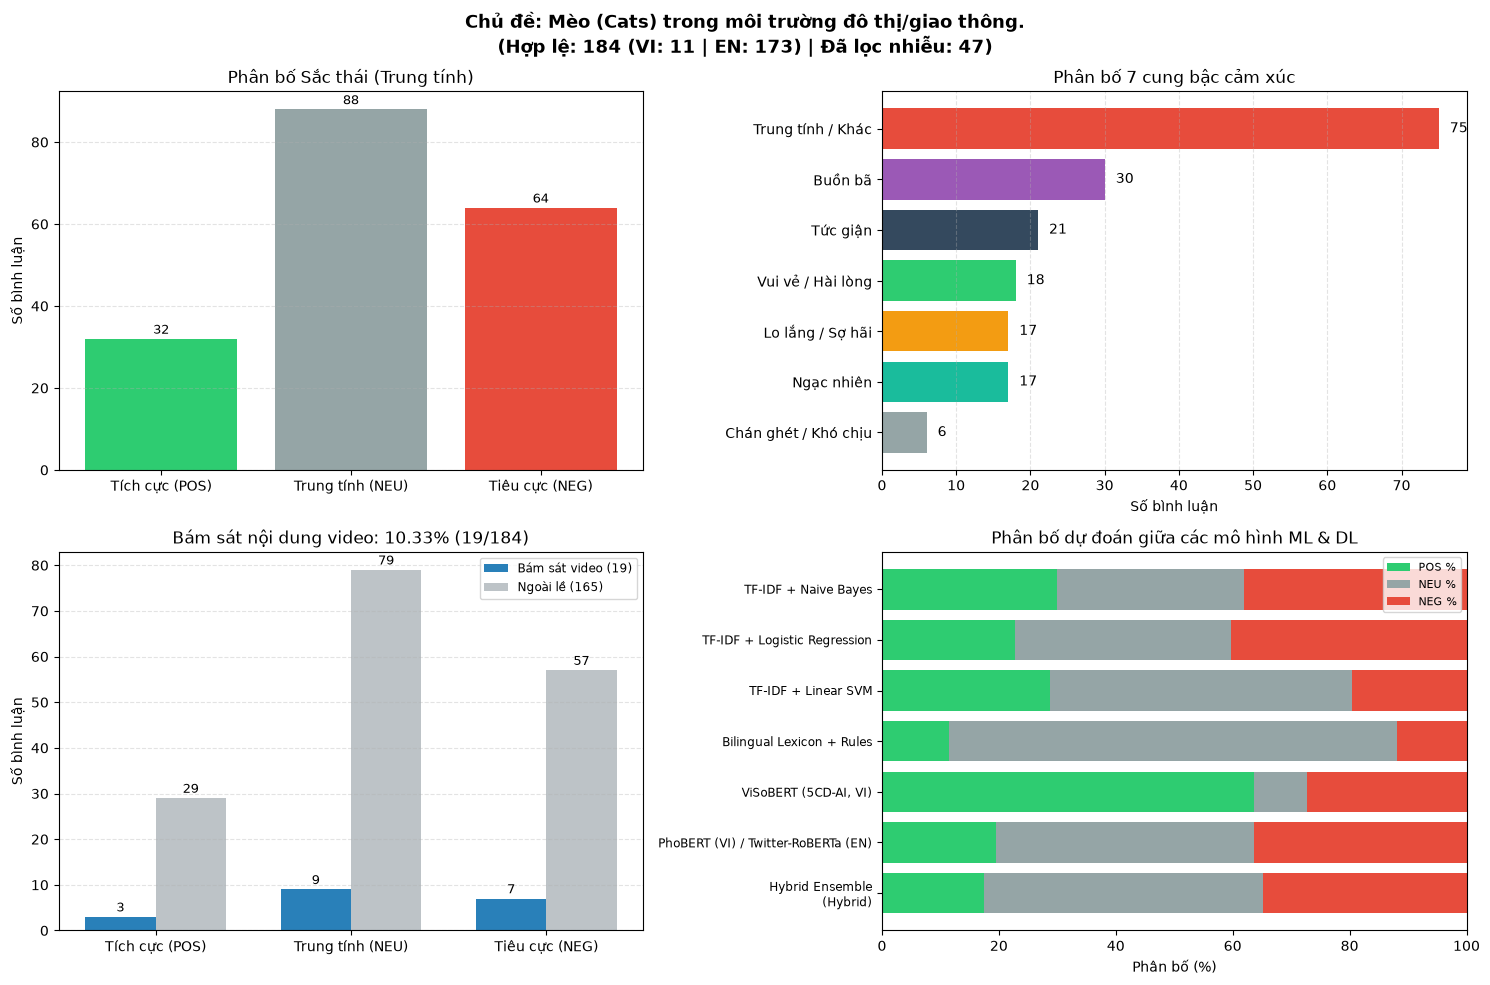

In [15]:
# === DASHBOARD TRỰC QUAN HÓA ===
if report.get("prepare_only"):
    print("Đang ở chế độ PREPARE_ONLY=True (không vẽ dashboard).")
else:
    summary = report.get("sentiment_summary") or {}
    if summary.get("total_valid_comments", 0) > 0:
        exported = report.get("exported_files", {})
        chart_path = exported.get("dashboard_png") or (OUTPUT_DIR / report["run_name"] / "dashboard.png")
        fig = plot_sentiment_dashboard(report, save_path=chart_path)
        plt.show()
    else:
        print("Không có bình luận hợp lệ để vẽ dashboard.")